### SatSCan for Cluster detection (Piran MSci)

In [4]:
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from pathlib import Path

In [71]:
prediction_path = Path('/Users/wm722/Documents/SCDs/results/UK/UK_Depression_Predictions.shp')
boundary_path = Path('/Users/wm722/Documents/SCDs/results/UK/QGIS/Countries_December_2023_Boundaries_UK_BFE_-4029370810466201423/CTRY_DEC_2023_UK_BFE.shp')


In [ ]:
import geopandas as gpd, numpy as np
import shapely

s = 500
g = gpd.read_file(prediction_path).to_crs(27700)

pts = shapely.point_on_surface(g.geometry.values)
px, py = shapely.get_x(pts), shapely.get_y(pts)

x0, y0, x1, y1 = g.total_bounds
nx, ny = int(np.ceil((x1 - x0) / s)), int(np.ceil((y1 - y0) / s))

counts = np.histogram2d(px, py, bins=[nx, ny],
                        range=[[x0, x0 + nx * s], [y0, y0 + ny * s]])[0]
cnt = counts.ravel().astype(int)

ix, iy = np.meshgrid(np.arange(nx), np.arange(ny), indexing="ij")
xc = (x0 + (ix + 0.5) * s).ravel()
yc = (y0 + (iy + 0.5) * s).ravel()

aoi = g.simplify(s / 10).buffer(s / 4).union_all()
shapely.prepare(aoi)

cells = shapely.box(xc - s / 2, yc - s / 2, xc + s / 2, yc + s / 2)
inside = shapely.contains(aoi, cells)
edge = ~inside & shapely.intersects(aoi, cells)

area = np.zeros(cells.shape)
area[inside] = s * s
area[edge] = shapely.area(shapely.intersection(cells[edge], aoi))

# any cell with points needs a usable baseline
area = np.where((cnt > 0) & (area < 0.1 * s * s), 0.1 * s * s, area)

keep = area > 0
ids = np.arange(cells.size)[keep]
assert cnt[keep].sum() == len(pts), "points lost"

np.savetxt("c.geo", np.c_[ids, xc[keep], yc[keep]], fmt="%d %.1f %.1f")
np.savetxt("c.cas", np.c_[ids, cnt[keep]], fmt="%d %d")
np.savetxt("c.pop", np.c_[ids, np.full(ids.size, 2024), area[keep]], fmt="%d %d %.1f")

In [8]:
from pyproj import Transformer

to_ll = Transformer.from_crs(27700, 4326, always_xy=True)
lon, lat = to_ll.transform(xc[keep], yc[keep])

# SaTScan lat/long files are ID, latitude, longitude (lat first)
np.savetxt("c.geo", np.c_[ids, lat, lon], fmt="%d %.6f %.6f")


In [ ]:
import geopandas as gpd, numpy as np, rasterio
from rasterio.transform import from_origin
from scipy.ndimage import gaussian_filter, distance_transform_edt

boundary = boundary_path     # boundary = "aoi.shp" if you have one
s, h, k = 250, 2000, 12              # cell (m), fine bandwidth (m), coarse/fine ratio

g = gpd.read_file(prediction_path).to_crs(27700)
p = g.geometry.representative_point()

x0, y0, x1, y1 = g.total_bounds
pad = k * h
x0, y0, x1, y1 = x0 - pad, y0 - pad, x1 + pad, y1 + pad
nx, ny = int(np.ceil((x1 - x0) / s)), int(np.ceil((y1 - y0) / s))
tf = from_origin(x0, y1 + (ny * s - (y1 - y0)), s, s)

cnt = np.histogram2d(p.y, p.x, bins=[ny, nx],
                     range=[[y0, y0 + ny * s], [x0, x0 + nx * s]])[0][::-1]

if boundary:
    from rasterio import features
    b = gpd.read_file(boundary).to_crs(27700)
    m = features.rasterize(((geom, 1) for geom in b.geometry), out_shape=(ny, nx),
                           transform=tf, dtype="uint8").astype(float)
else:
    m = (distance_transform_edt(cnt == 0) <= pad / s).astype(float)   # data dilated by pad

def dens(sig):
    f = lambda a: gaussian_filter(a, sig, mode="constant")
    return f(cnt) / np.maximum(f(m), 1e-9)

fine, coarse = dens(h / s), dens(k * h / s)
floor = 0.05 * cnt.sum() / m.sum()
dog = (fine - coarse) * 1e6 / s**2                    # polygons per km2
lr = np.log((fine + floor) / (coarse + floor))
dog[m == 0] = lr[m == 0] = np.nan

for name, a in (("dog", dog), ("logratio", lr)):
    with rasterio.open(f"{name}.tif", "w", driver="GTiff", height=ny, width=nx, count=1,
                       dtype="float32", crs=g.crs, transform=tf, nodata=np.nan) as d:
        d.write(a.astype("float32"), 1)

In [67]:
with rasterio.open("dog.tif") as d:
    data = d.read(1)

In [68]:
std = np.nanstd(data)
display(std)

np.float32(0.4319785)

In [69]:
positive = np.where(data > 1.5 *std, data, 0)

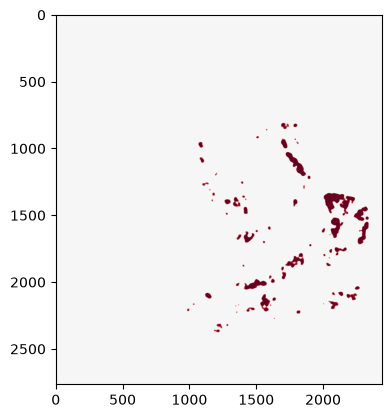

In [70]:
plt.figure()
plt.imshow(positive, cmap="RdBu_r", vmin=-np.percentile(positive, 99), vmax=np.percentile(positive, 99))